In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# 1. Create Grid

start = (2, 0)
goal = (0, 2)

actions = ["Up", "Down", "Left", "Right"]

# (2, 0) means robot starts at the bottom-left.
# (0, 2) means the destination is at the top-right.


In [3]:
# 2. Create Q-Table

q_table = np.zeros((9, 4))

before = q_table.copy()

# Why 9 and 4?
#  9 = 9 cells in our 3 × 3 grid.
# 4 = 4 possible actions.

In [4]:
# 3. Learning Settings

learning_rate = 0.1
discount_factor = 0.9

episodes = 1000

# The robot repeats the learning process 1,000 times.
# One episode = one attempt to reach the goal.

In [5]:
# 4. Train the Robot

# Two possibilities:
# ->20% chance: Try a random direction (Exploration).
# -> 80% chance: Choose the action with the highest Q-value (Exploitation).

for episode in range(episodes):

    position = start

    for step in range(30):

        # Find current state
        row, col = position
        state = row * 3 + col

        # Select an action
        if np.random.random() < 0.2:
            action = np.random.randint(4)
        else:
            action = np.argmax(q_table[state])

        # Move the robot
        row, col = position

        if action == 0:
            row = row - 1
        elif action == 1:
            row = row + 1
        elif action == 2:
            col = col - 1
        else:
            col = col + 1

        # Stay inside the grid
        row = max(0, min(row, 2))
        col = max(0, min(col, 2))

        new_position = (row, col)

        # Reaching the goal = +10 reward.
        # Every other move = -1 penalty.

        # Give reward
        if new_position == goal:
            reward = 10
        else:
            reward = -1

        new_state = row * 3 + col

        # Update Q-Table
        old_value = q_table[state, action]

        if new_position == goal:
            future_value = 0
        else:
            future_value = np.max(q_table[new_state])

        q_table[state, action] = old_value + learning_rate * (reward + discount_factor * future_value - old_value)

# The robot checks its previous action value,
#  considers the reward and future possibilities, and improves its Q-Table.

        position = new_position

        if position == goal:
            break

In [6]:
# 5. Display Q-Tables

print("BEFORE LEARNING")

print(pd.DataFrame(before, columns=actions))

print("\nAFTER LEARNING")

print(pd.DataFrame(q_table.round(2), columns=actions))

BEFORE LEARNING
    Up  Down  Left  Right
0  0.0   0.0   0.0    0.0
1  0.0   0.0   0.0    0.0
2  0.0   0.0   0.0    0.0
3  0.0   0.0   0.0    0.0
4  0.0   0.0   0.0    0.0
5  0.0   0.0   0.0    0.0
6  0.0   0.0   0.0    0.0
7  0.0   0.0   0.0    0.0
8  0.0   0.0   0.0    0.0

AFTER LEARNING
      Up  Down  Left  Right
0   0.79  0.27  1.48   7.99
1   7.97  6.19  6.08  10.00
2   0.00  0.00  0.00   0.00
3   4.05  1.54  1.21   6.20
4   8.00  4.51  4.42   7.89
5  10.00  0.88  1.18   2.64
6   4.54  3.11  3.11   4.58
7   6.20  4.55  3.10   5.98
8   7.95  0.42  1.75   1.53


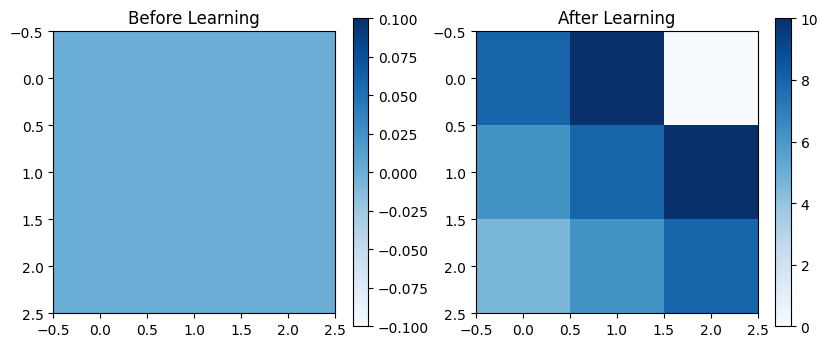

In [7]:
# 6. Show Before and After Graph

before_values = np.max(before, axis=1).reshape(3, 3)
after_values = np.max(q_table, axis=1).reshape(3, 3)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(before_values, cmap="Blues")
plt.title("Before Learning")
plt.colorbar()

plt.subplot(1, 2, 2)
plt.imshow(after_values, cmap="Blues")
plt.title("After Learning")
plt.colorbar()

plt.show()

# The heatmap shows the highest Q-value in each cell, not all four action values


In [8]:
# 7. Find Learned Path

position = start
path = [position]

for step in range(9):

    row, col = position
    state = row * 3 + col

    action = np.argmax(q_table[state])

    if action == 0:
        row = row - 1
    elif action == 1:
        row = row + 1
    elif action == 2:
        col = col - 1
    else:
        col = col + 1

    row = max(0, min(row, 2))
    col = max(0, min(col, 2))

    position = (row, col)
    path.append(position)

    if position == goal:
        break

print("\nAI LEARNED PATH:")
print(path)


AI LEARNED PATH:
[(2, 0), (2, 1), (1, 1), (0, 1), (0, 2)]


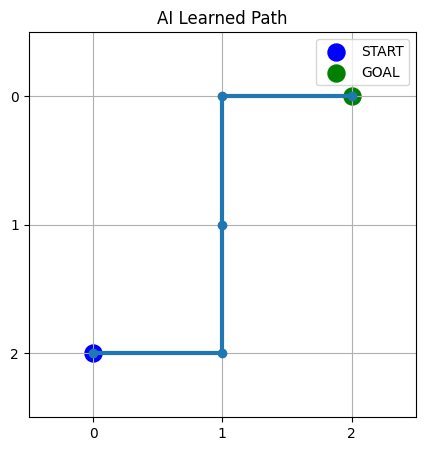

In [9]:
# 8. Draw Learned Path

x = [col for row, col in path]
y = [row for row, col in path]

plt.figure(figsize=(5, 5))

plt.plot(x, y, marker="o", linewidth=3)

plt.scatter(0, 2, color="blue", s=150, label="START")
plt.scatter(2, 0, color="green", s=150, label="GOAL")

plt.xlim(-0.5, 2.5)
plt.ylim(2.5, -0.5)

plt.xticks(range(3))
plt.yticks(range(3))

plt.grid()
plt.legend()
plt.title("AI Learned Path")

plt.show()

